##Task 1 – Data Acquisition and Exploration

In [ ]:
!pip install wfdb scipy scikit-learn matplotlib seaborn pandas numpy

In [ ]:
import os
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt
from collections import Counter

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Download MIT-BIH Arrhythmia Database
data_dir = "/content/mitdb"

os.makedirs(data_dir, exist_ok=True)

records = wfdb.get_record_list("mitdb")

wfdb.dl_database(
    "mitdb",
    dl_dir=data_dir,
    records=records
)

print("Total recordings available:", len(records))
print("Dataset downloaded successfully!")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [ ]:
# Records containing paced rhythms
paced_records = ['102', '104', '107', '217']

# Keep remaining recordings
usable_records = [
    record for record in records
    if record not in paced_records
]

print("Total records:", len(records))
print("Paced records removed:", len(paced_records))
print("Usable records:", len(usable_records))
print(usable_records)

Total records: 48
Paced records removed: 4
Usable records: 44
['100', '101', '103', '105', '106', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


In [ ]:
# Load record 100
record_path = os.path.join(data_dir, "100")

record = wfdb.rdrecord(record_path)
annotation = wfdb.rdann(record_path, "atr")

# Extract ECG signal
ecg_signal = record.p_signal

print("Signal shape:", ecg_signal.shape)
print("Sampling frequency:", record.fs)
print("Number of annotations:", len(annotation.sample))
print("ECG channels:", record.sig_name)


Signal shape: (650000, 2)
Sampling frequency: 360
Number of annotations: 2274
ECG channels: ['MLII', 'V5']


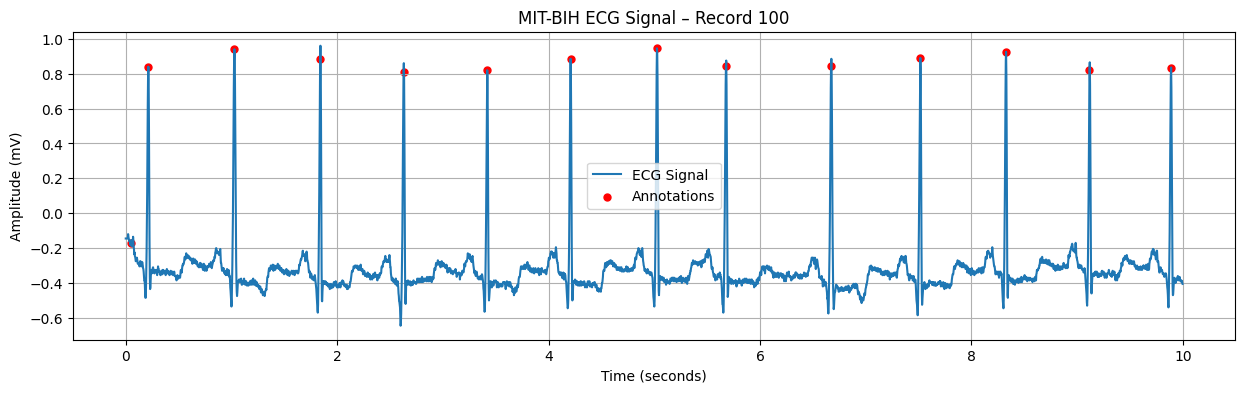

In [ ]:
# Select first ECG channel
signal = ecg_signal[:, 0]

# Plot first 10 seconds
duration = 10
samples = int(duration * record.fs)

plt.figure(figsize=(15, 4))

plt.plot(
    np.arange(samples) / record.fs,
    signal[:samples],
    label="ECG Signal"
)

# Mark heartbeat annotations
beat_samples = [
    s for s in annotation.sample
    if s < samples
]

plt.scatter(
    np.array(beat_samples) / record.fs,
    signal[beat_samples],
    color='red',
    s=25,
    label="Annotations"
)

plt.title("MIT-BIH ECG Signal – Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# Map MIT-BIH annotation symbols to AAMI classes
aami_mapping = {
    'N': 'N',
    'L': 'N',
    'R': 'N',
    'e': 'N',
    'j': 'N',

    'A': 'S',
    'a': 'S',
    'J': 'S',
    'S': 'S',

    'V': 'V',
    'E': 'V',

    'F': 'F',

    '/': 'Q',
    'f': 'Q',
    'Q': 'Q'
}

print("AAMI class mapping created!")


AAMI class mapping created!


In [ ]:
# Count annotation symbols in record 100
symbol_counts = Counter(annotation.symbol)

print("Annotation symbol distribution:\n")

for symbol, count in symbol_counts.items():
    print(f"{symbol}: {count}")


Annotation symbol distribution:

+: 1
N: 2239
A: 33
V: 1


In [ ]:
# Store heartbeat labels from all records
all_labels = []
record_labels = {}

for rec in usable_records:

    rec_path = os.path.join(data_dir, rec)

    # Load annotations
    ann = wfdb.rdann(rec_path, "atr")

    labels = []

    for symbol in ann.symbol:

        # Keep only recognized heartbeat annotations
        if symbol in aami_mapping:
            labels.append(aami_mapping[symbol])

    record_labels[rec] = labels
    all_labels.extend(labels)

print("Total annotated beats:", len(all_labels))
print("Total records processed:", len(record_labels))


Total annotated beats: 100733
Total records processed: 44


AAMI Class Distribution:

N    90125
S     2781
V     7009
F      803
Q       15
Name: count, dtype: int64


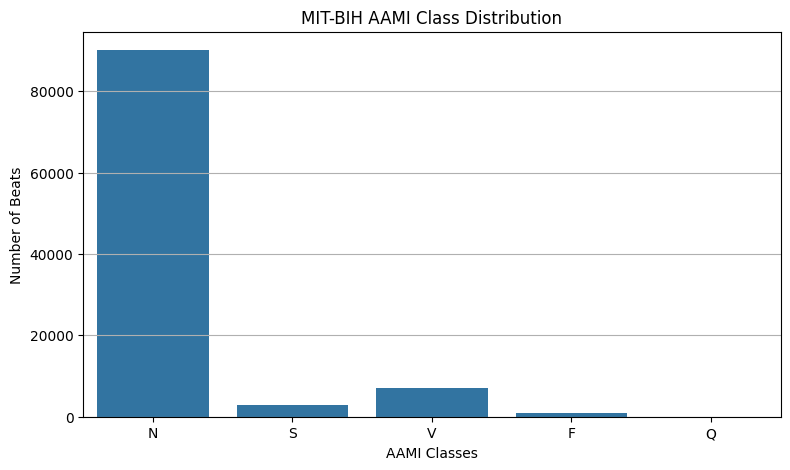

In [ ]:
# Calculate class counts
class_counts = pd.Series(all_labels).value_counts()

# Maintain AAMI class order
class_order = ['N', 'S', 'V', 'F', 'Q']

class_counts = class_counts.reindex(
    class_order, fill_value=0
)

print("AAMI Class Distribution:\n")
print(class_counts)

# Plot distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("MIT-BIH AAMI Class Distribution")
plt.xlabel("AAMI Classes")
plt.ylabel("Number of Beats")
plt.grid(axis='y')
plt.show()


In [ ]:
# Calculate class percentages
class_percentages = (
    class_counts / class_counts.sum()
) * 100

distribution_df = pd.DataFrame({
    "Class": class_counts.index,
    "Beat Count": class_counts.values,
    "Percentage": class_percentages.values
})

print(distribution_df.to_string(index=False))


Class  Beat Count  Percentage
    N       90125   89.469191
    S        2781    2.760764
    V        7009    6.957998
    F         803    0.797157
    Q          15    0.014891


##Task 2 – Data Preprocessing

In [ ]:
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [ ]:
# ECG preprocessing settings
fs = 360

lowcut = 0.5
highcut = 40.0

before = 180
after = 180

window_size = before + after

# AAMI class order
class_order = ['N', 'S', 'V', 'F', 'Q']

# Convert labels into numerical values
label_to_id = {
    label: index for index, label in enumerate(class_order)
}

print("Window size:", window_size)
print("Window duration:", window_size / fs, "seconds")
print("Class mapping:", label_to_id)


Window size: 360
Window duration: 1.0 seconds
Class mapping: {'N': 0, 'S': 1, 'V': 2, 'F': 3, 'Q': 4}


In [ ]:
# Create Butterworth bandpass filter
def filter_ecg(signal):

    sos = butter(
        4,
        [lowcut, highcut],
        btype='bandpass',
        fs=fs,
        output='sos'
    )

    filtered_signal = sosfiltfilt(sos, signal)

    return filtered_signal

print("Butterworth filter function created!")


Butterworth filter function created!


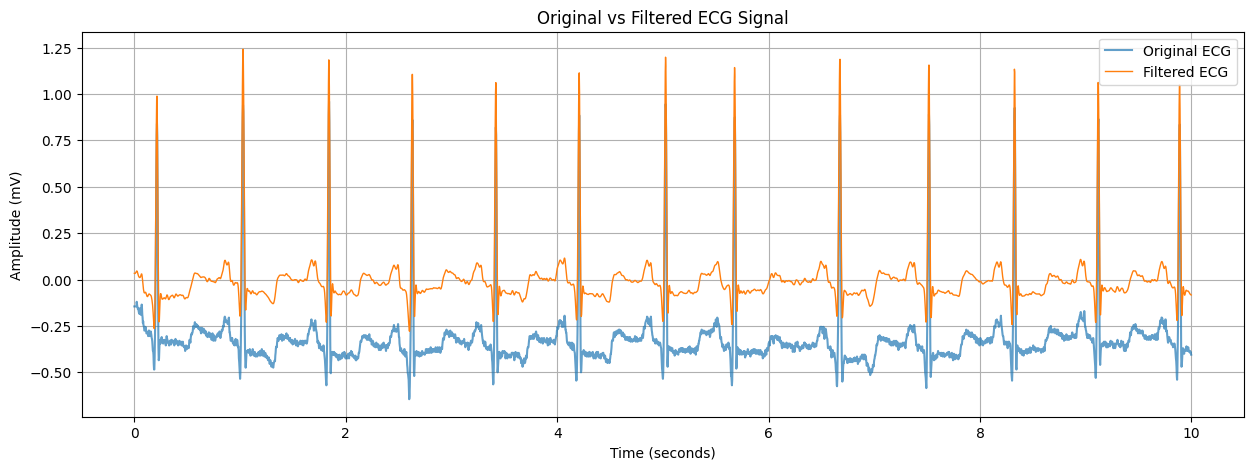

In [ ]:
# Load record 100
record_path = os.path.join(data_dir, "100")

record = wfdb.rdrecord(record_path)

original_signal = record.p_signal[:, 0]

# Apply filtering
filtered_signal = filter_ecg(original_signal)

# Plot first 10 seconds
samples = 10 * fs
time_axis = np.arange(samples) / fs

plt.figure(figsize=(15, 5))

plt.plot(
    time_axis,
    original_signal[:samples],
    label="Original ECG",
    alpha=0.7
)

plt.plot(
    time_axis,
    filtered_signal[:samples],
    label="Filtered ECG",
    linewidth=1
)

plt.title("Original vs Filtered ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# Extract fixed-length windows around annotated beats
def segment_beats(signal, annotation_samples, annotation_symbols):

    beats = []
    labels = []

    for sample, symbol in zip(annotation_samples, annotation_symbols):

        # Ignore non-beat annotations
        if symbol not in aami_mapping:
            continue

        # Check window boundaries
        start = sample - before
        end = sample + after

        if start < 0 or end > len(signal):
            continue

        # Extract ECG beat
        beat = signal[start:end]

        # Add beat and its AAMI label
        beats.append(beat)
        labels.append(aami_mapping[symbol])

    return beats, labels

print("Beat segmentation function created!")


Beat segmentation function created!


In [ ]:
# Store all extracted beats, labels and patient IDs
all_beats = []
all_beat_labels = []
all_patient_ids = []

for rec in usable_records:

    rec_path = os.path.join(data_dir, rec)

    # Load ECG recording and annotations
    record = wfdb.rdrecord(rec_path)
    annotation = wfdb.rdann(rec_path, "atr")

    # Select first ECG channel
    signal = record.p_signal[:, 0]

    # Remove noise
    filtered_signal = filter_ecg(signal)

    # Extract individual beats
    beats, labels = segment_beats(
        filtered_signal,
        annotation.sample,
        annotation.symbol
    )

    # Store extracted data
    all_beats.extend(beats)
    all_beat_labels.extend(labels)
    all_patient_ids.extend([rec] * len(beats))

    print(f"Record {rec}: {len(beats)} beats extracted")

# Convert into NumPy arrays
X = np.array(all_beats, dtype=np.float32)
y = np.array(all_beat_labels)
groups = np.array(all_patient_ids)

print("\nBeat extraction completed!")
print("ECG data shape:", X.shape)
print("Labels shape:", y.shape)
print("Patient IDs shape:", groups.shape)


Record 100: 2271 beats extracted
Record 101: 1864 beats extracted
Record 103: 2083 beats extracted
Record 105: 2572 beats extracted
Record 106: 2027 beats extracted
Record 108: 1762 beats extracted
Record 109: 2530 beats extracted
Record 111: 2124 beats extracted
Record 112: 2537 beats extracted
Record 113: 1793 beats extracted
Record 114: 1879 beats extracted
Record 115: 1951 beats extracted
Record 116: 2411 beats extracted
Record 117: 1534 beats extracted
Record 118: 2277 beats extracted
Record 119: 1987 beats extracted
Record 121: 1861 beats extracted
Record 122: 2474 beats extracted
Record 123: 1517 beats extracted
Record 124: 1618 beats extracted
Record 200: 2600 beats extracted
Record 201: 1962 beats extracted
Record 202: 2135 beats extracted
Record 203: 2979 beats extracted
Record 205: 2655 beats extracted
Record 207: 1859 beats extracted
Record 208: 2953 beats extracted
Record 209: 3004 beats extracted
Record 210: 2648 beats extracted
Record 212: 2747 beats extracted
Record 213

In [ ]:
# Normalize each heartbeat individually
beat_mean = np.mean(X, axis=1, keepdims=True)
beat_std = np.std(X, axis=1, keepdims=True)

X = (X - beat_mean) / (beat_std + 1e-8)

# Reshape for RNN, LSTM and GRU models
X = X.reshape(X.shape[0], X.shape[1], 1)

print("Normalization completed!")
print("Final ECG data shape:", X.shape)


Normalization completed!
Final ECG data shape: (100682, 360, 1)


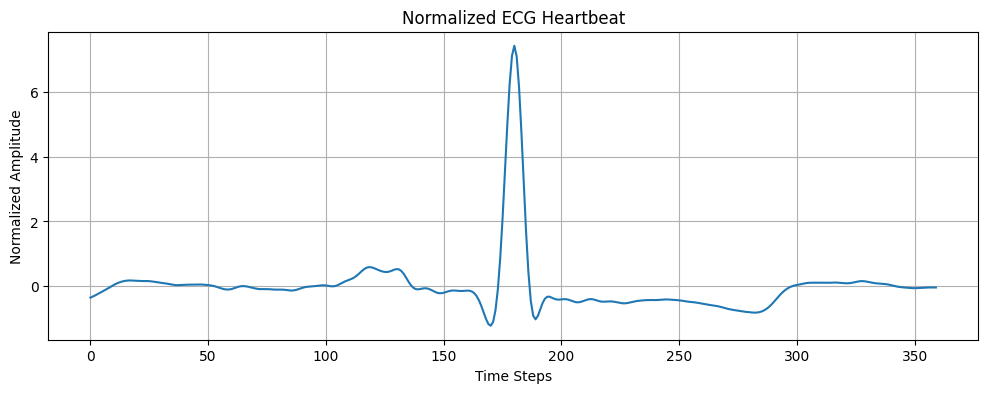

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(X[0, :, 0])

plt.title("Normalized ECG Heartbeat")
plt.xlabel("Time Steps")
plt.ylabel("Normalized Amplitude")
plt.grid()
plt.show()


In [ ]:
# Standard MIT-BIH AAMI patient-wise division
ds1_records = [
    '101', '106', '108', '109', '112', '114',
    '115', '116', '118', '119', '122', '124',
    '201', '203', '205', '207', '208', '209',
    '215', '220', '223', '230'
]

ds2_records = [
    '100', '103', '105', '111', '113', '117',
    '121', '123', '200', '202', '210', '212',
    '213', '214', '219', '221', '222', '228',
    '231', '232', '233', '234'
]

# Check that all selected records are available
available_records = set(usable_records)

assert set(ds1_records + ds2_records) == available_records, \
    "Record lists do not match the downloaded usable records!"

print("DS1 patients:", len(ds1_records))
print("DS2 patients:", len(ds2_records))


DS1 patients: 22
DS2 patients: 22


In [ ]:
# Identify DS1 and DS2 beat indices
ds1_indices = np.where(np.isin(groups, ds1_records))[0]
ds2_indices = np.where(np.isin(groups, ds2_records))[0]

# Split DS1 by patient ID
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_local, val_local = next(
    splitter.split(
        X[ds1_indices],
        y[ds1_indices],
        groups[ds1_indices]
    )
)

# Get original indices
train_indices = ds1_indices[train_local]
val_indices = ds1_indices[val_local]
test_indices = ds2_indices

# Create datasets
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

# Patient IDs for each set
train_groups = groups[train_indices]
val_groups = groups[val_indices]
test_groups = groups[test_indices]

print("Training shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Testing shape:", X_test.shape, y_test.shape)

print("\nTraining patients:", len(np.unique(train_groups)))
print("Validation patients:", len(np.unique(val_groups)))
print("Testing patients:", len(np.unique(test_groups)))


Training shape: (39989, 360, 1) (39989,)
Validation shape: (11006, 360, 1) (11006,)
Testing shape: (49687, 360, 1) (49687,)

Training patients: 17
Validation patients: 5
Testing patients: 22


In [ ]:
# Check patient separation
train_patients = set(train_groups)
val_patients = set(val_groups)
test_patients = set(test_groups)

print("Train-Validation overlap:",
      train_patients.intersection(val_patients))

print("Train-Test overlap:",
      train_patients.intersection(test_patients))

print("Validation-Test overlap:",
      val_patients.intersection(test_patients))

assert len(train_patients & val_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(val_patients & test_patients) == 0

print("\nNo patient overlap! Inter-patient split verified.")


Train-Validation overlap: set()
Train-Test overlap: set()
Validation-Test overlap: set()

No patient overlap! Inter-patient split verified.


Class Distribution:

   Training  Validation  Testing
N     36240        9601    44235
S       736         208     1837
V      2598        1190     3220
F       413           1      388
Q         2           6        7


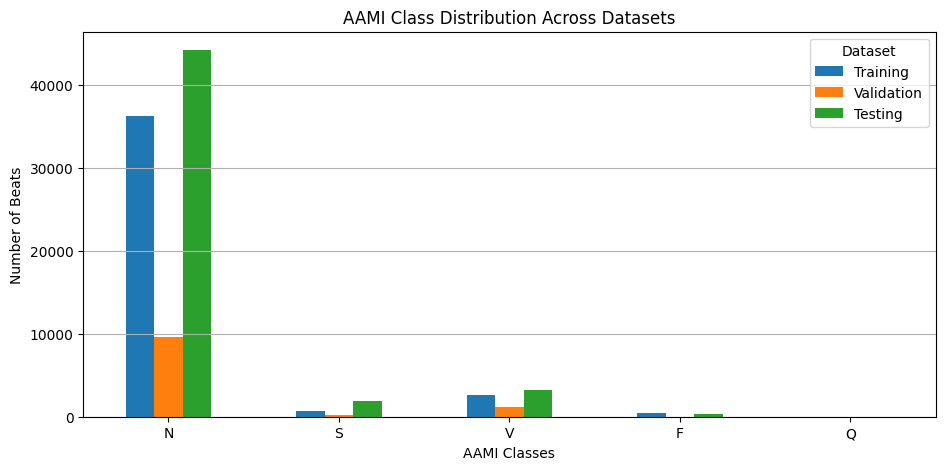

In [ ]:
# Display class distribution for each dataset
split_distribution = pd.DataFrame({
    "Training": pd.Series(y_train).value_counts(),
    "Validation": pd.Series(y_val).value_counts(),
    "Testing": pd.Series(y_test).value_counts()
}).reindex(class_order, fill_value=0)

print("Class Distribution:\n")
print(split_distribution)

# Visualize distribution
split_distribution.plot(
    kind='bar',
    figsize=(11, 5)
)

plt.title("AAMI Class Distribution Across Datasets")
plt.xlabel("AAMI Classes")
plt.ylabel("Number of Beats")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.legend(title="Dataset")
plt.show()


In [ ]:
# Convert class labels into numerical values
y_train_encoded = np.array([
    label_to_id[label] for label in y_train
])

y_val_encoded = np.array([
    label_to_id[label] for label in y_val
])

y_test_encoded = np.array([
    label_to_id[label] for label in y_test
])

# Calculate weights using training data only
present_classes = np.unique(y_train_encoded)

weights = compute_class_weight(
    class_weight='balanced',
    classes=present_classes,
    y=y_train_encoded
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(present_classes, weights)
}

print("Class weights:\n")

for cls, weight in class_weights.items():
    print(f"{class_order[cls]}: {weight:.4f}")


Class weights:

N: 0.2207
S: 10.8666
V: 3.0784
F: 19.3651
Q: 3998.9000


In [ ]:
print("========== FINAL DATASET SUMMARY ==========")

print("\nTraining:")
print("X_train:", X_train.shape)
print("y_train:", y_train_encoded.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val_encoded.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test_encoded.shape)

print("\nNumber of classes:", len(class_order))
print("Classes:", class_order)

print("\nNumber of training patients:",
      len(np.unique(train_groups)))

print("Number of validation patients:",
      len(np.unique(val_groups)))

print("Number of testing patients:",
      len(np.unique(test_groups)))

print("\nPreprocessing completed successfully!")


========== FINAL DATASET SUMMARY ==========

Training:
X_train: (39989, 360, 1)
y_train: (39989,)

Validation:
X_val: (11006, 360, 1)
y_val: (11006,)

Testing:
X_test: (49687, 360, 1)
y_test: (49687,)

Number of classes: 5
Classes: ['N', 'S', 'V', 'F', 'Q']

Number of training patients: 17
Number of validation patients: 5
Number of testing patients: 22

Preprocessing completed successfully!


##Task 3 – Model Training and Evaluation

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
#verifying input data
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nNumber of output classes:", len(class_order))
print("Class labels:", label_to_id)

# Check training classes
print("\nTraining class counts:")

for i, cls in enumerate(class_order):
    print(f"{cls}: {np.sum(y_train_encoded == i)}")

# Ensure all five classes are present in training
assert len(np.unique(y_train_encoded)) == 5, \
    "One or more AAMI classes are missing from training data!"

print("\nData verification completed!")


Training data: (39989, 360, 1)
Validation data: (11006, 360, 1)
Testing data: (49687, 360, 1)

Number of output classes: 5
Class labels: {'N': 0, 'S': 1, 'V': 2, 'F': 3, 'Q': 4}

Training class counts:
N: 36240
S: 736
V: 2598
F: 413
Q: 2

Data verification completed!


In [ ]:
# Build RNN, LSTM and GRU models using the same architecture
def build_model(model_type):

    model = Sequential()

    model.add(Input(shape=(window_size, 1)))

    if model_type == "RNN":
        model.add(SimpleRNN(64))

    elif model_type == "LSTM":
        model.add(LSTM(64))

    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dropout(0.2))

    model.add(Dense(32, activation='relu'))

    model.add(Dense(5, activation='softmax'))

    # Compile model
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Model-building function created!")


Model-building function created!


In [ ]:
# Common training configuration
EPOCHS = 30
BATCH_SIZE = 128

# Early stopping callback
def get_early_stopping():

    return EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

# Store trained models and histories
models = {}
histories = {}
training_times = {}

print("Training configuration ready!")


Training configuration ready!


In [ ]:
# Build RNN model
rnn_model = build_model("RNN")

rnn_model.summary()

# Train RNN
start_time = time.time()

rnn_history = rnn_model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[get_early_stopping()],
    verbose=1
)

training_times["RNN"] = time.time() - start_time

models["RNN"] = rnn_model
histories["RNN"] = rnn_history

print("\nRNN training completed!")
print("Training time:", round(training_times["RNN"], 2), "seconds")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,469 (25.27 KB)

 Trainable params: 6,469 (25.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 175ms/step - accuracy: 0.1834 - loss: 1.5752 - val_accuracy: 0.1315 - val_loss: 1.3695
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 163ms/step - accuracy: 0.1739 - loss: 1.8589 - val_accuracy: 0.1194 - val_loss: 1.5024
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 93ms/step - accuracy: 0.2191 - loss: 1.6333 - val_accuracy: 0.2174 - val_loss: 1.2626
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 94ms/step - accuracy: 0.2642 - loss: 1.9475 - val_accuracy: 0.3499 - val_loss: 1.3517
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.2632 - loss: 1.7728 - val_accuracy: 0.2149 - val_loss: 1.4613
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.2292 - loss: 2.0677 - val_accuracy: 0.0705 - val_loss: 1.5962
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 93ms/step - accuracy: 0.1830 - loss: 1.9309 - val_accuracy: 0.1004 - val_loss: 1.6433
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.1807 - loss: 1.9615 

In [ ]:
# Build LSTM model
lstm_model = build_model("LSTM")

lstm_model.summary()

# Train LSTM
start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[get_early_stopping()],
    verbose=1
)

training_times["LSTM"] = time.time() - start_time

models["LSTM"] = lstm_model
histories["LSTM"] = lstm_history

print("\nLSTM training completed!")
print("Training time:", round(training_times["LSTM"], 2), "seconds")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,141 (74.77 KB)

 Trainable params: 19,141 (74.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 156s 490ms/step - accuracy: 0.0418 - loss: 1.5736 - val_accuracy: 0.0441 - val_loss: 1.4190
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 149s 476ms/step - accuracy: 0.2294 - loss: 1.5310 - val_accuracy: 0.4519 - val_loss: 1.3172
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 150s 479ms/step - accuracy: 0.3940 - loss: 1.4763 - val_accuracy: 0.6229 - val_loss: 1.3571
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 155s 496ms/step - accuracy: 0.1454 - loss: 1.7899 - val_accuracy: 0.0689 - val_loss: 1.5159
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 152s 486ms/step - accuracy: 0.0595 - loss: 1.5550 - val_accuracy: 0.0393 - val_loss: 1.4647
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 202s 487ms/step - accuracy: 0.0494 - loss: 1.4089 - val_accuracy: 0.0398 - val_loss: 1.4433
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 150s 480ms/step - accuracy: 0.0617 - loss: 1.4193 - val_accuracy: 0.0459 - val_loss: 1.4922
Epoch 7: early stopping
Restoring model weights from the end of the best epo

In [ ]:
# Build GRU model
gru_model = build_model("GRU")

gru_model.summary()

# Train GRU
start_time = time.time()

gru_history = gru_model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[get_early_stopping()],
    verbose=1
)

training_times["GRU"] = time.time() - start_time

models["GRU"] = gru_model
histories["GRU"] = gru_history

print("\nGRU training completed!")
print("Training time:", round(training_times["GRU"], 2), "seconds")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109 (59.02 KB)

 Trainable params: 15,109 (59.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 191s 605ms/step - accuracy: 0.1510 - loss: 1.5537 - val_accuracy: 0.0334 - val_loss: 1.4408
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 193s 616ms/step - accuracy: 0.0973 - loss: 1.6833 - val_accuracy: 0.0359 - val_loss: 1.5205
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 189s 603ms/step - accuracy: 0.0667 - loss: 1.4284 - val_accuracy: 0.0364 - val_loss: 1.5416
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 219s 657ms/step - accuracy: 0.0864 - loss: 1.3756 - val_accuracy: 0.0362 - val_loss: 1.5716
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 189s 603ms/step - accuracy: 0.0789 - loss: 1.3030 - val_accuracy: 0.0389 - val_loss: 1.5727
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 190s 607ms/step - accuracy: 0.0769 - loss: 1.2906 - val_accuracy: 0.0413 - val_loss: 1.5866
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.

GRU training completed!
Training time: 1170.48 seconds


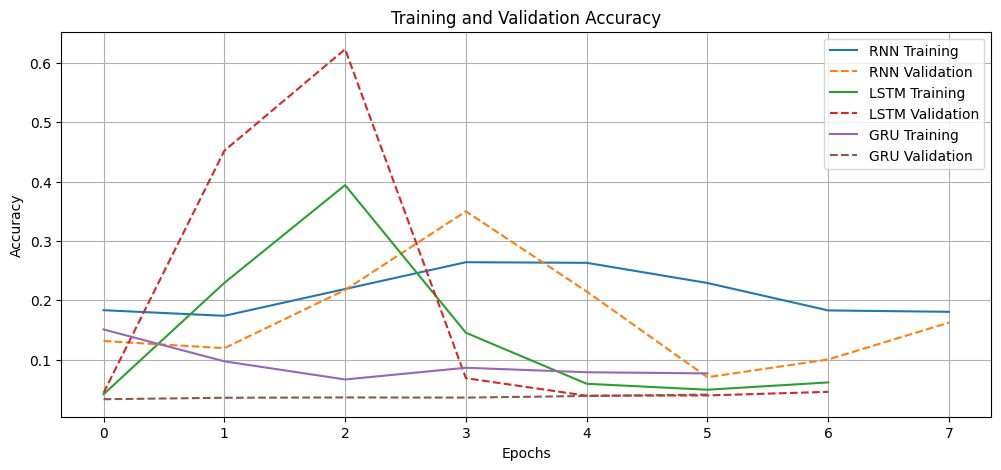

In [ ]:
plt.figure(figsize=(12, 5))

for name, history in histories.items():

    plt.plot(
        history.history['accuracy'],
        label=f'{name} Training'
    )

    plt.plot(
        history.history['val_accuracy'],
        linestyle='--',
        label=f'{name} Validation'
    )

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


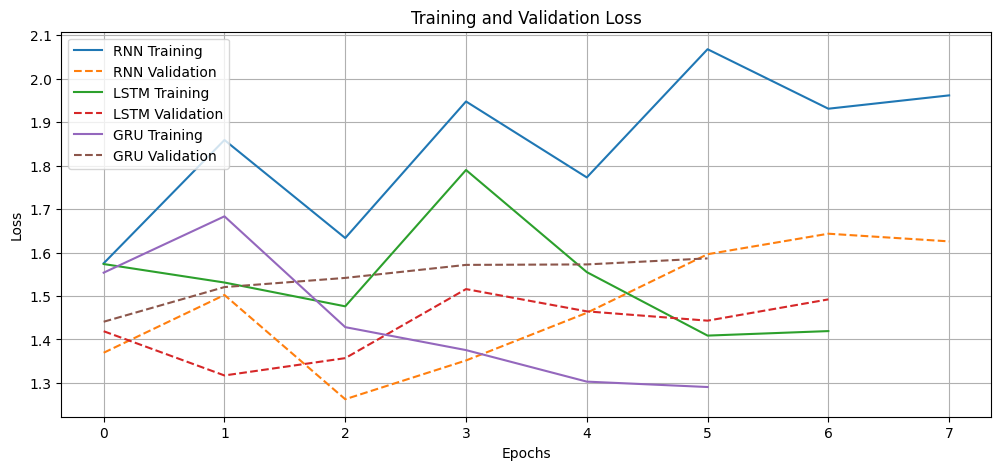

In [ ]:
plt.figure(figsize=(12, 5))

for name, history in histories.items():

    plt.plot(
        history.history['loss'],
        label=f'{name} Training'
    )

    plt.plot(
        history.history['val_loss'],
        linestyle='--',
        label=f'{name} Validation'
    )

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# Store evaluation results
results = {}

# Store predicted labels
predictions = {}

for name, model in models.items():

    print(f"\nEvaluating {name} model...")

    # Predict probabilities
    y_prob = model.predict(X_test, verbose=0)

    # Convert probabilities into class predictions
    y_pred = np.argmax(y_prob, axis=1)

    predictions[name] = y_pred

    # Calculate performance metrics
    accuracy = accuracy_score(y_test_encoded, y_pred)

    precision_macro = precision_score(
        y_test_encoded, y_pred,
        average='macro',
        zero_division=0
    )

    recall_macro = recall_score(
        y_test_encoded, y_pred,
        average='macro',
        zero_division=0
    )

    f1_macro = f1_score(
        y_test_encoded, y_pred,
        average='macro',
        zero_division=0
    )

    precision_weighted = precision_score(
        y_test_encoded, y_pred,
        average='weighted',
        zero_division=0
    )

    recall_weighted = recall_score(
        y_test_encoded, y_pred,
        average='weighted',
        zero_division=0
    )

    f1_weighted = f1_score(
        y_test_encoded, y_pred,
        average='weighted',
        zero_division=0
    )

    results[name] = {
        "Accuracy": accuracy,
        "Precision (Macro)": precision_macro,
        "Recall (Macro)": recall_macro,
        "F1 (Macro)": f1_macro,
        "Precision (Weighted)": precision_weighted,
        "Recall (Weighted)": recall_weighted,
        "F1 (Weighted)": f1_weighted,
        "Training Time (sec)": training_times[name]
    }

print("\nAll models evaluated successfully!")



Evaluating RNN model...

Evaluating LSTM model...

Evaluating GRU model...

All models evaluated successfully!


In [ ]:
for name, y_pred in predictions.items():

    print("\n" + "=" * 50)
    print(f"{name} CLASSIFICATION REPORT")
    print("=" * 50)

    print(
        classification_report(
            y_test_encoded,
            y_pred,
            labels=[0, 1, 2, 3, 4],
            target_names=class_order,
            zero_division=0
        )
    )



RNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

           N       0.93      0.06      0.11     44235
           S       0.03      0.34      0.05      1837
           V       0.05      0.37      0.09      3220
           F       0.00      0.02      0.01       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.09     49687
   macro avg       0.20      0.16      0.05     49687
weighted avg       0.83      0.09      0.11     49687


LSTM CLASSIFICATION REPORT
              precision    recall  f1-score   support

           N       0.89      0.48      0.63     44235
           S       0.05      0.30      0.09      1837
           V       0.15      0.48      0.23      3220
           F       0.00      0.04      0.01       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.47     49687
   macro avg       0.22      0.26      0.19     49687
weighted avg       0.8

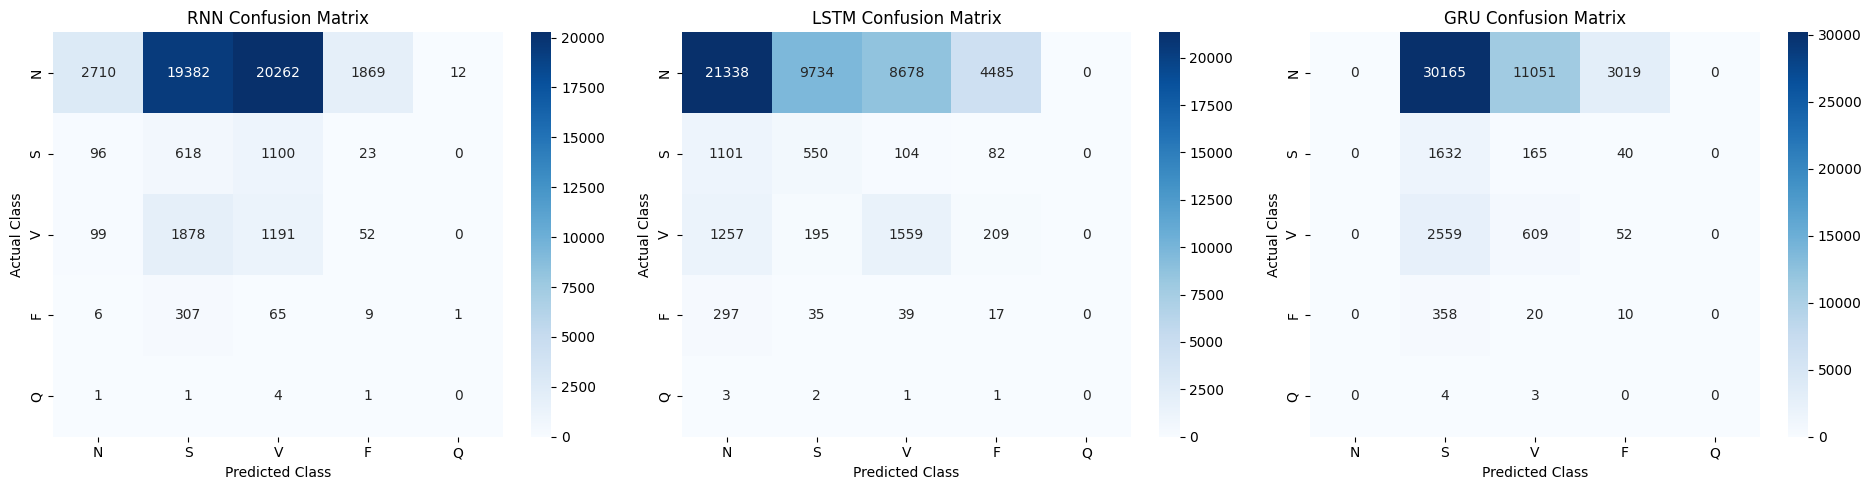

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test_encoded,
        y_pred,
        labels=[0, 1, 2, 3, 4]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_order,
        yticklabels=class_order,
        ax=ax
    )

    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [ ]:
# Convert results into a DataFrame
comparison_df = pd.DataFrame(results).T

# Display results
print("FINAL MODEL PERFORMANCE COMPARISON\n")

print(comparison_df.round(4).to_string())

# Identify best model based on macro F1-score
best_model = comparison_df["F1 (Macro)"].idxmax()

print("\nBest performing model:", best_model)
print(
    "Best Macro F1-score:",
    round(comparison_df.loc[best_model, "F1 (Macro)"], 4)
)


FINAL MODEL PERFORMANCE COMPARISON

      Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  Precision (Weighted)  Recall (Weighted)  F1 (Weighted)  Training Time (sec)
RNN     0.0911             0.2031          0.1582      0.0533                0.8330             0.0911         0.1103             365.5954
LSTM    0.4722             0.2191          0.2620      0.1901                0.8034             0.4722         0.5750            1115.1960
GRU     0.0453             0.0203          0.2207      0.0352                0.0051             0.0453         0.0086            1170.4776

Best performing model: LSTM
Best Macro F1-score: 0.1901


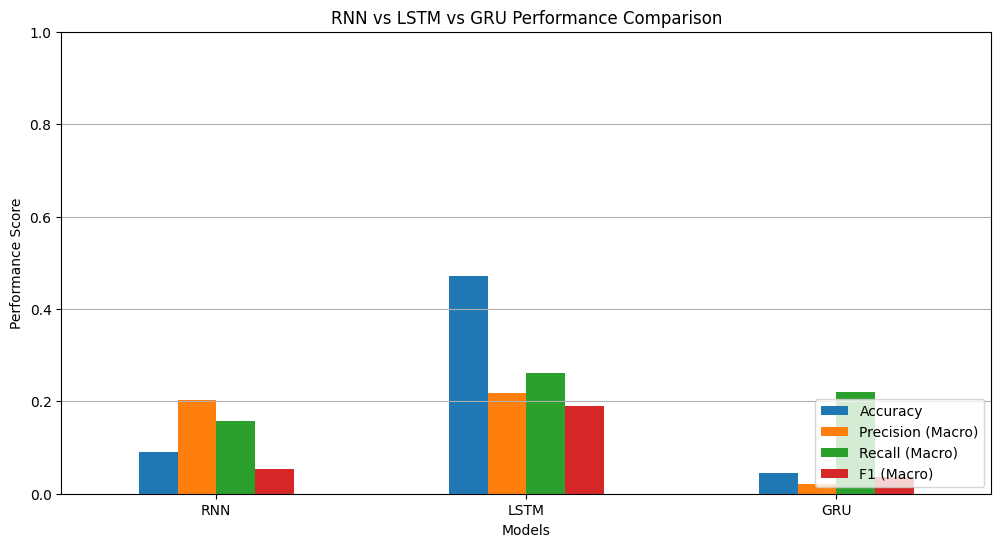

In [ ]:
# Compare important evaluation metrics
metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1 (Macro)"
]

comparison_df[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()


In [ ]:
print("=" * 55)
print("FINAL MODEL EVALUATION")
print("=" * 55)

for name, row in comparison_df.iterrows():

    print(f"\n{name} Model")
    print(f"Accuracy  : {row['Accuracy']:.4f}")
    print(f"Precision : {row['Precision (Macro)']:.4f}")
    print(f"Recall    : {row['Recall (Macro)']:.4f}")
    print(f"F1-score  : {row['F1 (Macro)']:.4f}")
    print(f"Training Time: {row['Training Time (sec)']:.2f} sec")

print("\n" + "=" * 55)
print("BEST MODEL:", best_model)
print("=" * 55)


FINAL MODEL EVALUATION

RNN Model
Accuracy  : 0.0911
Precision : 0.2031
Recall    : 0.1582
F1-score  : 0.0533
Training Time: 365.60 sec

LSTM Model
Accuracy  : 0.4722
Precision : 0.2191
Recall    : 0.2620
F1-score  : 0.1901
Training Time: 1115.20 sec

GRU Model
Accuracy  : 0.0453
Precision : 0.0203
Recall    : 0.2207
F1-score  : 0.0352
Training Time: 1170.48 sec

BEST MODEL: LSTM
